# Módulo 5 — Práctica Día 8: interpolación a estación y métricas

Ejercicios de la práctica del **Día 8** (ver [`README.md`](../README.md)).
Todos los datos de este notebook son reales: estaciones de OGIMET
(observación pura: Perú; comparación con WRF/ERA5-Land: dominio real del
WRF) y el `wrfout`/ERA5-Land reales del Módulo 4/5.

> **📍 Nota para curso con 2 grupos:** desde el Ejercicio 2, el notebook usa **Salto** como estación de ejemplo (compartida por toda la clase). Cada grupo repite los Ejercicios 2-3 con sus propias 3 estaciones asignadas:
> - **Grupo 1 (Norte):** Iguazú, Resistencia, Salto.
> - **Grupo 2 (Sur):** Rosario, Ezeiza, Carrasco.
> Basta con cambiar `c = coords["Salto"]` y el archivo `data/obs/Salto_2024_12_13_horario.csv` por el nombre de cada estación — el resto de la celda no cambia.

## Ejercicio 1 — Carga de observaciones (30 min)

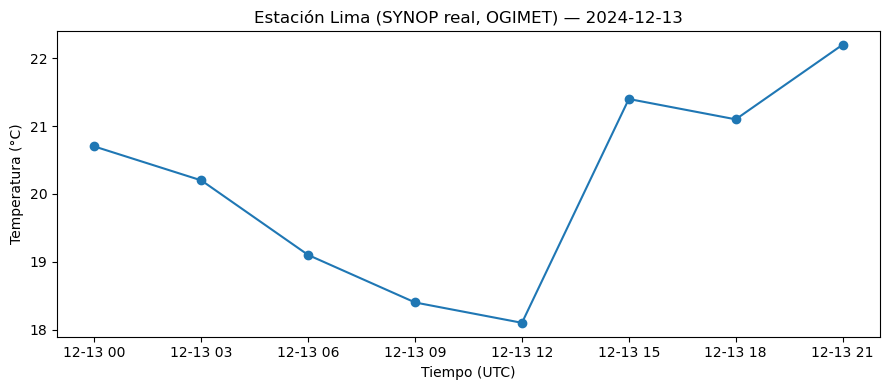

n = 8 reportes (Lima reporta cada 3 h, no cada hora)


tiempo
2024-12-13 00:00:00    20.7
2024-12-13 03:00:00    20.2
2024-12-13 06:00:00    19.1
2024-12-13 09:00:00    18.4
2024-12-13 12:00:00    18.1
2024-12-13 15:00:00    21.4
2024-12-13 18:00:00    21.1
2024-12-13 21:00:00    22.2
Name: temp_C, dtype: float64

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Estación real de Perú -- este ejercicio es puramente de carga/inspección,
# no requiere correspondencia con el dominio del WRF (eso viene en el Ejercicio 2).
obs_lima = pd.read_csv("../../../data/obs/Lima_2024_12_13_horario.csv",
                        index_col="tiempo", parse_dates=True)["temp_C"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(obs_lima.index, obs_lima.values, "o-")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Estación Lima (SYNOP real, OGIMET) — 2024-12-13")
fig.tight_layout()
plt.show()

print(f"n = {len(obs_lima)} reportes (Lima reporta cada 3 h, no cada hora)")
obs_lima

## Ejercicio 2 — Interpolación del WRF al punto de estación (40 min)

Lima no sirve para el resto de la práctica: el dominio real del WRF de
muestra (proyecto bigua) no cubre Perú, así que no hay ningún punto de
grilla que corresponda físicamente a Lima. De acá en adelante usamos
**Salto** (Uruguay), una de las 6 estaciones reales que sí están dentro del
dominio (`data/ogimet/coords_area_wrf.json`), y el **día completo**
(24 horas UTC del `wrfout` real, `data/grid_muestra/wrfout_muestra.nc`). La
"interpolación" ya no se simula: se calcula tomando el punto de grilla más
cercano a las coordenadas reales de Salto, igual que en el Módulo 4.

/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Series alineadas: mismo índice temporal, longitud 24


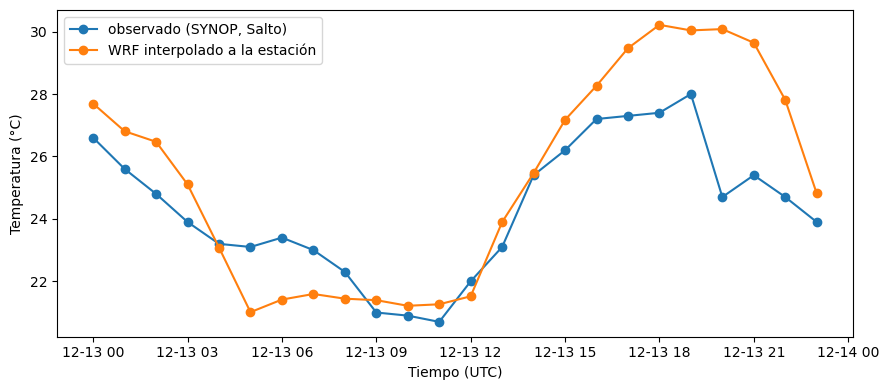

In [2]:
import json
import numpy as np
import xarray as xr

coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))
c = coords["Salto"]

# wrfout_muestra.nc: dia completo (24 horas), solo variables de superficie.
# No trae SINALPHA/COSALPHA -- no hacen falta: el Modulo 4 establecio que en
# este dominio (Mercator) U10/V10 crudos YA son earth-relative.
ds_wrf = xr.open_dataset("../../../data/grid_muestra/wrfout_muestra.nc")

def punto_mas_cercano(ds, lat, lon):
    dist2 = (ds["XLAT"] - lat) ** 2 + (ds["XLONG"] - lon) ** 2
    return np.unravel_index(np.argmin(dist2.values), dist2.shape)

iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
tiempos = pd.to_datetime(ds_wrf["XTIME"].values)

obs_horaria = pd.read_csv("../../../data/obs/Salto_2024_12_13_horario.csv",
                           parse_dates=["tiempo"]).set_index("tiempo")
obs_estacion = obs_horaria.reindex(tiempos)["temp_C"]
obs_estacion.name = "obs"

wrf_en_estacion = pd.Series(
    (ds_wrf["T2"].isel(south_north=iy, west_east=ix) - 273.15).values,
    index=tiempos, name="wrf",
)

# Verificar alineacion temporal antes de comparar
assert (wrf_en_estacion.index == obs_estacion.index).all(), "Las series no están alineadas en el tiempo"
print("Series alineadas: mismo índice temporal, longitud", len(obs_estacion))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(obs_estacion.index, obs_estacion.values, "o-", label="observado (SYNOP, Salto)")
ax.plot(wrf_en_estacion.index, wrf_en_estacion.values, "o-", label="WRF interpolado a la estación")
ax.set_xlabel("Tiempo (UTC)"); ax.set_ylabel("Temperatura (°C)")
ax.legend()
fig.tight_layout()
plt.show()

## Ejercicio 3 — Cálculo manual de métricas (50 min)

In [3]:
def calcular_mae(s, o):
    return float(np.mean(np.abs(s - o)))

def calcular_rmse(s, o):
    return float(np.sqrt(np.mean((s - o) ** 2)))

def calcular_bias(s, o):
    return float(np.mean(s - o))

def calcular_r(s, o):
    return float(np.corrcoef(s, o)[0, 1])

def calcular_kge(s, o):
    r = calcular_r(s, o)
    beta = np.mean(s) / np.mean(o)
    alpha = np.std(s) / np.std(o)
    kge = 1 - np.sqrt((r - 1) ** 2 + (beta - 1) ** 2 + (alpha - 1) ** 2)
    return kge, {"r": r, "beta": beta, "alpha": alpha}


s, o = wrf_en_estacion.values, obs_estacion.values
mae, rmse, bias, r = calcular_mae(s, o), calcular_rmse(s, o), calcular_bias(s, o), calcular_r(s, o)
kge, comp = calcular_kge(s, o)

print(f"MAE  = {mae:.3f} °C")
print(f"RMSE = {rmse:.3f} °C")
print(f"bias = {bias:.3f} °C  ({'sobreestimación' if bias > 0 else 'subestimación'})")
print(f"r    = {r:.3f}")
print(f"KGE  = {kge:.3f}  (r={comp['r']:.3f}, beta={comp['beta']:.3f}, alpha={comp['alpha']:.3f})")

MAE  = 1.540 °C
RMSE = 1.997 °C
bias = 0.962 °C  (sobreestimación)
r    = 0.888
KGE  = 0.405  (r=0.888, beta=1.040, alpha=1.584)


**Interpretación (a completar por el participante):** con `bias > 0`, el
WRF real **sobreestima** la temperatura en Salto a lo largo del día;
`r≈0.89` indica que el patrón diurno (ciclo de calentamiento/enfriamiento)
se sigue muy bien a pesar del sesgo — el mismo caso que motiva no confiar
solo en `r`, ahora con datos reales y un día completo.

## Ejercicio 4 — Caso de contraste: dos formas distintas de fallar (30 min)

En vez de fabricar dos casos con RMSE igualado a propósito, comparamos dos
fuentes **reales** contra la misma observación en Salto, con el día
completo: el WRF (Ejercicio 2) y ERA5-Land. No van a tener el mismo RMSE
— son datos reales, no un ejemplo de libro de texto — pero eso no importa:
lo interesante es *por qué* fallan distinto.

In [4]:
era5 = xr.open_dataset("../../../data/era_muestra/era5_land_20241213.nc")

era5_en_estacion = pd.Series(
    era5["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15,
    index=tiempos, name="era5",
)

for nombre, caso in [("WRF", wrf_en_estacion), ("ERA5-Land", era5_en_estacion)]:
    s2, o2 = caso.values, obs_estacion.values
    kge2, comp2 = calcular_kge(s2, o2)
    print(f"{nombre}:")
    print(f"  RMSE = {calcular_rmse(s2, o2):.3f} | bias = {calcular_bias(s2, o2):.3f} | "
          f"r = {comp2['r']:.3f} | beta = {comp2['beta']:.3f} | alpha = {comp2['alpha']:.3f} | KGE = {kge2:.3f}")

WRF:
  RMSE = 1.997 | bias = 0.962 | r = 0.888 | beta = 1.040 | alpha = 1.584 | KGE = 0.405
ERA5-Land:
  RMSE = 1.466 | bias = 0.664 | r = 0.787 | beta = 1.027 | alpha = 0.710 | KGE = 0.639


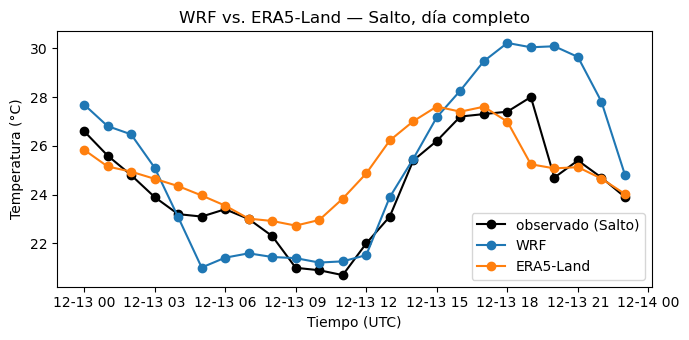

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(obs_estacion.index, obs_estacion.values, "ko-", label="observado (Salto)")
ax.plot(wrf_en_estacion.index, wrf_en_estacion.values, "o-", label="WRF")
ax.plot(era5_en_estacion.index, era5_en_estacion.values, "o-", label="ERA5-Land")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("WRF vs. ERA5-Land — Salto, día completo")
ax.legend()
fig.tight_layout()
plt.show()

In [6]:
respuesta = '''
Con el dia completo, WRF y ERA5-Land YA NO tienen RMSE parecido en Salto
(WRF ~2.0 grados, ERA5-Land ~1.5) -- ERA5-Land es mejor en RMSE Y en KGE.
Pero la comparacion sigue siendo instructiva por COMO fallan distinto,
algo que RMSE por si solo no muestra.

WRF: bias positivo (sobreestima ~1.0 grado en promedio), r alto (~0.89,
sigue muy bien el ciclo diurno), pero alpha = 1.58 -- la temperatura del
WRF varia MAS de lo real a lo largo del dia (esta sobre-dispersado):
exagera la amplitud del ciclo diurno.

ERA5-Land: bias tambien positivo y de magnitud parecida (~0.7 grados),
r un poco mas bajo (~0.79), pero alpha = 0.71 -- varia MENOS de lo real
(esta sub-dispersado): suaviza el ciclo diurno mas de la cuenta.

Conclusion: los dos modelos tienen sesgos parecidos en signo y magnitud,
pero fallan en direcciones OPUESTAS en variabilidad -- uno exagera el
ciclo diurno, el otro lo aplana. Esa diferencia queda invisible si solo se
mira RMSE o bias; el componente alpha del KGE es el que la revela. Con
datos reales, casi nunca vamos a encontrar el ejemplo perfecto de libro de
texto (mismo RMSE) -- pero la leccion de fondo (descomponer el error, no
mirar una sola metrica) vale igual o mas.
'''
print(respuesta)


Con el dia completo, WRF y ERA5-Land YA NO tienen RMSE parecido en Salto
(WRF ~2.0 grados, ERA5-Land ~1.5) -- ERA5-Land es mejor en RMSE Y en KGE.
Pero la comparacion sigue siendo instructiva por COMO fallan distinto,
algo que RMSE por si solo no muestra.

WRF: bias positivo (sobreestima ~1.0 grado en promedio), r alto (~0.89,
sigue muy bien el ciclo diurno), pero alpha = 1.58 -- la temperatura del
WRF varia MAS de lo real a lo largo del dia (esta sobre-dispersado):
exagera la amplitud del ciclo diurno.

ERA5-Land: bias tambien positivo y de magnitud parecida (~0.7 grados),
r un poco mas bajo (~0.79), pero alpha = 0.71 -- varia MENOS de lo real
(esta sub-dispersado): suaviza el ciclo diurno mas de la cuenta.

Conclusion: los dos modelos tienen sesgos parecidos en signo y magnitud,
pero fallan en direcciones OPUESTAS en variabilidad -- uno exagera el
ciclo diurno, el otro lo aplana. Esa diferencia queda invisible si solo se
mira RMSE o bias; el componente alpha del KGE es el que la rev

## Cierre

Entregable del día: módulo `metricas.py` (celda siguiente) + este notebook.

In [7]:
codigo = '''# Metricas de validacion (Modulo 5)
import numpy as np


def calcular_mae(s, o):
    return float(np.mean(np.abs(s - o)))


def calcular_rmse(s, o):
    return float(np.sqrt(np.mean((s - o) ** 2)))


def calcular_bias(s, o):
    return float(np.mean(s - o))


def calcular_r(s, o):
    return float(np.corrcoef(s, o)[0, 1])


def calcular_kge(s, o):
    r = calcular_r(s, o)
    beta = np.mean(s) / np.mean(o)
    alpha = np.std(s) / np.std(o)
    kge = 1 - np.sqrt((r - 1) ** 2 + (beta - 1) ** 2 + (alpha - 1) ** 2)
    return kge, {"r": r, "beta": beta, "alpha": alpha}
'''

with open("metricas.py", "w") as f:
    f.write(codigo)
print("Guardado: metricas.py")

Guardado: metricas.py


Continuar con
[`03_practica_dia9_taylor_addedvalue.ipynb`](03_practica_dia9_taylor_addedvalue.ipynb).